## Analýza družicových snímků Sentinel-2 pomocí knihovny `rasterio`

V tomto notebooku si ukážeme, jak pracovat s reálnými rastrovými daty dálkového průzkumu Země v Pythonu:

1. Vyhledání málo oblačné scény **Sentinel-2 Level-2A** přes **STAC API** a načtení výřezu zájmového území v knihovně `rasterio`.
2. Inspekce prostorových metadat, souřadnicového systému a převod souřadnic.
3. Porovnání přirozených barev (**RGB**) a nepravé barevné kompozice (**CIR**).
4. Výpočet vegetačního (**NDVI**) a vodního (**NDWI**) indexu, histogramy, 2D spektrální prostor a export výsledků.

In [3]:
!pip install rasterio pystac-client planetary-computer matplotlib numpy -q
print("Knihovny jsou připravené.")

Knihovny jsou připravené.


## 1. Vyhledání scény Sentinel-2 a načtení výřezu v `rasterio`

Místo stahování celého datového balíku ze sítě si vyhledáme málo oblačný snímek **Sentinel-2 Level-2A** pro zájmové území (výřez Prahy) přes **STAC API** a načteme jen ohraničený výřez pomocí `from_bounds` a `Window`.

Zajímají nás spektrální pásma s rozlišením 10 m:
- **B02** – modré (Blue)
- **B03** – zelené (Green)
- **B04** – červené (Red)
- **B08** – blízké infračervené (NIR)

In [4]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import pystac_client
import planetary_computer as pc

# Ohraničující obdélník (západ, jih, východ, sever) v WGS84 - okolí Prahy
bbox_wgs84 = [14.35, 50.04, 14.48, 50.12]

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox_wgs84,
    datetime="2024-05-01/2024-08-31",
    query={"eo:cloud_cover": {"lt": 15}},
)

items = list(search.items())
print(f"Počet nalezených scén: {len(items)}")

item = items[0]
print("Vybraná scéna:", item.id)
print("Datum pořízení:", item.datetime)
print("Oblačnost (%):", item.properties.get("eo:cloud_cover"))

def nacti_vyrez(asset_key, bbox_4326):
    href = item.assets[asset_key].href
    with rasterio.open(href) as src:
        bbox_crs = transform_bounds("EPSG:4326", src.crs, *bbox_4326)
        win = from_bounds(*bbox_crs, transform=src.transform).round_offsets().round_lengths()
        data = src.read(1, window=win).astype("float32")
        win_transform = src.window_transform(win)
        crs = src.crs
        res = src.res
    return data, win_transform, crs, res

blue, win_transform, crs, res = nacti_vyrez("B02", bbox_wgs84)
green, _, _, _ = nacti_vyrez("B03", bbox_wgs84)
red, _, _, _ = nacti_vyrez("B04", bbox_wgs84)
nir, _, _, _ = nacti_vyrez("B08", bbox_wgs84)

print(f"Rozměry výřezu (šířka x výška): {red.shape[1]} x {red.shape[0]} px")
print(f"Souřadnicový systém (CRS): {crs}")
print(f"Rozlišení pixelu: {res[0]} x {res[1]} m")

Počet nalezených scén: 4
Vybraná scéna: S2B_MSIL2A_20240721T100559_R022_T33UVR_20240721T145243
Datum pořízení: 2024-07-21 10:05:59.024000+00:00
Oblačnost (%): 11.500994
Rozměry výřezu (šířka x výška): 937 x 897 px
Souřadnicový systém (CRS): EPSG:32633
Rozlišení pixelu: 10.0 x 10.0 m


## 2. Přirozené barvy (RGB) a nepravá barevná kompozice (CIR)

Z načtených pásem si složíme dva klasické pohledy na krajinu:
- **RGB (Red – Green – Blue):** přirozené barvy blízké lidskému zraku.
- **CIR (NIR – Red – Green):** nepravá barevná kompozice, kde blízké infračervené pásmo (`B08`) namapujeme do červeného kanálu – vegetace díky vysokému odrazu v NIR vystupuje v červených až purpurových odstínech a vodní plochy působí tmavě.

Pro přehledné zobrazení snímku Sentinel-2 L2A upravíme rozsah odrazivosti (při úpravě kontrastu omezíme extrémně jasné hodnoty).

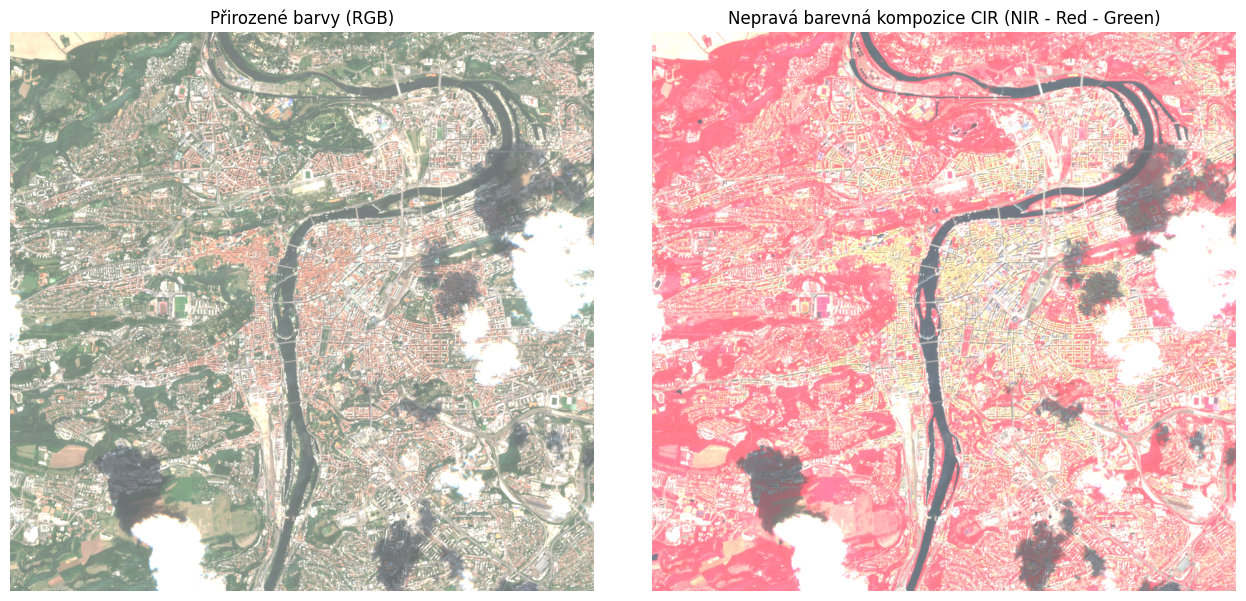

In [5]:
import matplotlib.pyplot as plt

# Úprava kontrastu pro přehledné vykreslení (odrazivost škálovaná v L2A)
vmax_vis = 2500.0
rgb_vis = np.clip(np.dstack((red, green, blue)) / vmax_vis, 0, 1)
cir_vis = np.clip(np.dstack((nir, red, green)) / vmax_vis, 0, 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

ax1.imshow(rgb_vis)
ax1.set_title("Přirozené barvy (RGB)")
ax1.axis("off")

ax2.imshow(cir_vis)
ax2.set_title("Nepravá barevná kompozice CIR (NIR - Red - Green)")
ax2.axis("off")

plt.tight_layout()
plt.show()

## 3. Spektrální indexy NDVI a NDWI a jejich histogramy

Nad načtenými pásmy Sentinel-2 spočítáme dva základní indexy dálkového průzkumu Země:
- **NDVI** (`(NIR - Red) / (NIR + Red)`) zvýrazňuje fotosynteticky aktivní vegetaci.
- **NDWI** (`(Green - NIR) / (Green + NIR)`) zvýrazňuje vodní plochy (např. tok Vltavy).

Histogramy nám ukážou rozdělení hodnot v celém výřezu a pomohou zdůvodnit volbu prahů při další analýze.

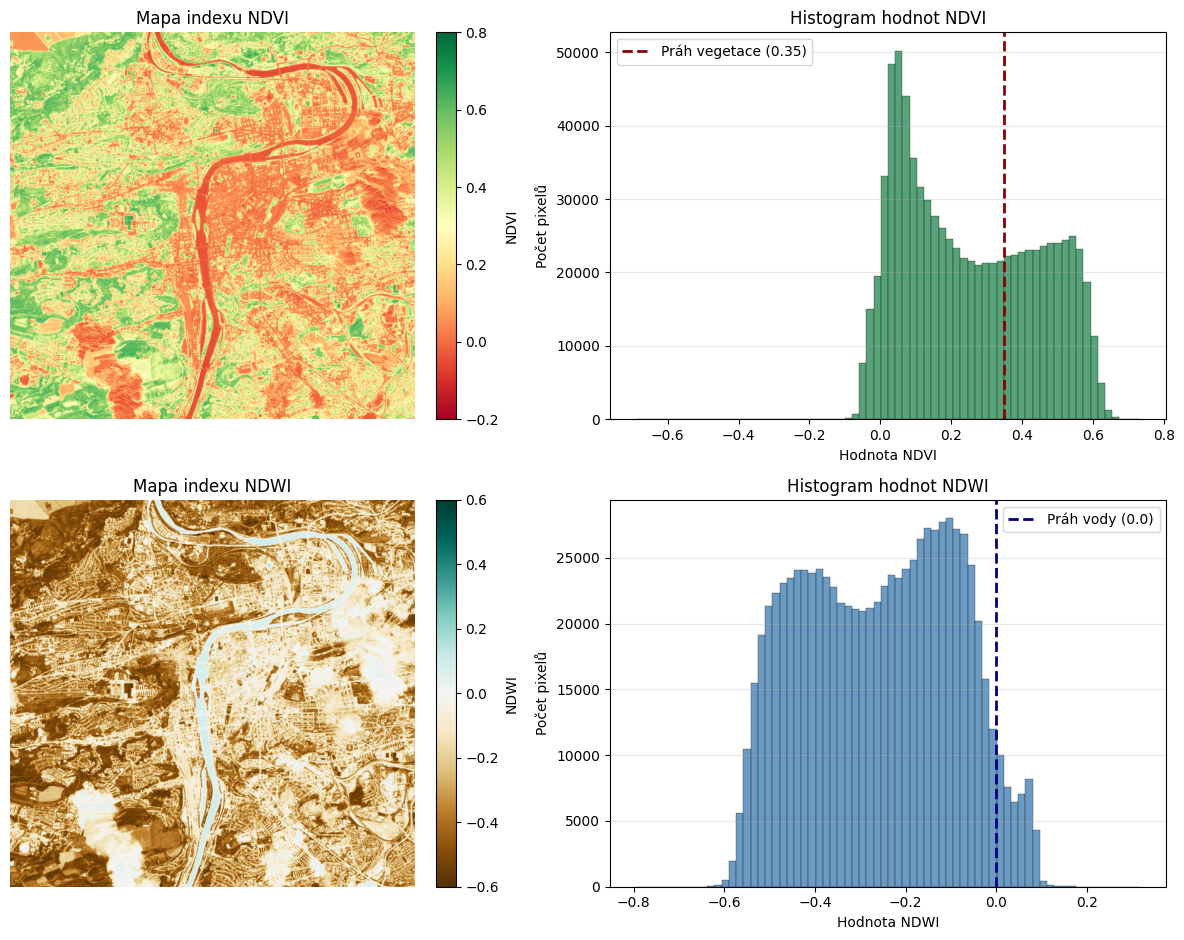

In [6]:
np.seterr(divide="ignore", invalid="ignore")

# Ošetření nulových pixelů mimo platná data (pokud by se vyskytly)
platne = (red > 0) & (green > 0) & (nir > 0)

ndvi = np.where(platne, (nir - red) / (nir + red), np.nan)
ndwi = np.where(platne, (green - nir) / (green + nir), np.nan)

prah_ndvi = 0.35
prah_ndwi = 0.0

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))

# 1. Mapa NDVI
im_ndvi = axes[0, 0].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8)
axes[0, 0].set_title("Mapa indexu NDVI")
axes[0, 0].axis("off")
plt.colorbar(im_ndvi, ax=axes[0, 0], fraction=0.046, pad=0.04, label="NDVI")

# 2. Histogram NDVI
ndvi_vals = ndvi[~np.isnan(ndvi)]
axes[0, 1].hist(ndvi_vals, bins=70, color="seagreen", alpha=0.8, edgecolor="black", linewidth=0.25)
axes[0, 1].axvline(prah_ndvi, color="darkred", linestyle="--", linewidth=2, label=f"Práh vegetace ({prah_ndvi})")
axes[0, 1].set_title("Histogram hodnot NDVI")
axes[0, 1].set_xlabel("Hodnota NDVI")
axes[0, 1].set_ylabel("Počet pixelů")
axes[0, 1].legend()
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Mapa NDWI
im_ndwi = axes[1, 0].imshow(ndwi, cmap="BrBG", vmin=-0.6, vmax=0.6)
axes[1, 0].set_title("Mapa indexu NDWI")
axes[1, 0].axis("off")
plt.colorbar(im_ndwi, ax=axes[1, 0], fraction=0.046, pad=0.04, label="NDWI")

# 4. Histogram NDWI
ndwi_vals = ndwi[~np.isnan(ndwi)]
axes[1, 1].hist(ndwi_vals, bins=70, color="steelblue", alpha=0.8, edgecolor="black", linewidth=0.25)
axes[1, 1].axvline(prah_ndwi, color="navy", linestyle="--", linewidth=2, label=f"Práh vody ({prah_ndwi})")
axes[1, 1].set_title("Histogram hodnot NDWI")
axes[1, 1].set_xlabel("Hodnota NDWI")
axes[1, 1].set_ylabel("Počet pixelů")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. 2D spektrální prostor (Red vs. NIR) a klasifikace ploch

V DPZ můžeme chování různých povrchů nahlédnout nejen v mapě, ale i ve **2D spektrálním prostoru** (např. závislost blízkého infračerveného pásma `NIR` na červeném pásmu `Red`). Tam se od sebe typicky oddělují vegetační plochy (vyšší `NIR`, nižší `Red`), vodní plochy a velmi jasné objekty (např. mraky).

Na základě hodnot **NDVI** a **NDWI** si pak pixely rozdělíme do několika přehledných kategorií a spočítáme jejich odhadovanou rozlohu v hektarech (při rozlišení 10 m × 10 m má jeden pixel 100 m², tedy 0,01 ha).

--- Odhadované plochy ve výřezu ---
Vegetace (NDVI ≥ 0.35)    :   2925.4 ha
Ostatní povrch            :   4340.0 ha
Voda (NDWI > 0)           :    446.6 ha
Velmi jasné / mraky       :    693.0 ha
Celkem platná plocha      :   8404.9 ha


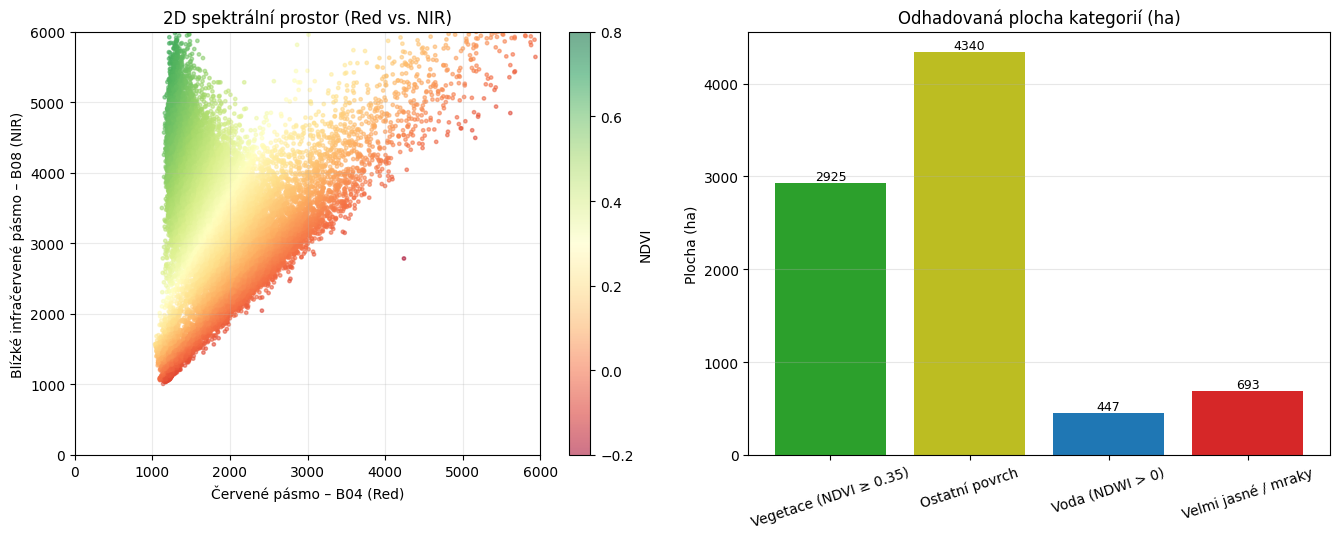

In [7]:
# Pro přehledný 2D bodový/hustotní graf použijeme vzorek platných pixelů (např. max. 25 000 bodů)
rng = np.random.default_rng(42)
idx_y, idx_x = np.where(platne)
n_samples = min(25000, len(idx_y))
sel = rng.choice(len(idx_y), size=n_samples, replace=False)

r_sub = red[idx_y[sel], idx_x[sel]]
nir_sub = nir[idx_y[sel], idx_x[sel]]
ndvi_sub = ndvi[idx_y[sel], idx_x[sel]]

# Klasifikace do 4 kategorií (jednoduché prahové rozdělení pro demonstraci)
# 1: Voda (NDWI > prah_ndwi a zároveň nízké NDVI)
# 2: Vegetace (NDVI >= prah_ndvi)
# 3: Velmi jasné / oblačnost (vysoká odrazivost v Red i NIR, nízké NDVI)
# 4: Ostatní povrch (zástavba, holá půda, nižší vegetace)
voda = platne & (ndwi > prah_ndwi) & (ndvi < 0.05)
vegetace = platne & (~voda) & (ndvi >= prah_ndvi)
jasne_mraky = platne & (~voda) & (~vegetace) & (red > 2800) & (nir > 2800)
ostatni = platne & (~voda) & (~vegetace) & (~jasne_mraky)

# Plocha jednoho pixelu: res[0] * res[1] m2 -> převod na hektary (1 ha = 10 000 m2)
plocha_pixelu_ha = (res[0] * res[1]) / 10000.0

kategorie = [
    ("Vegetace (NDVI ≥ 0.35)", vegetace, "#2ca02c"),
    ("Ostatní povrch", ostatni, "#bcbd22"),
    ("Voda (NDWI > 0)", voda, "#1f77b4"),
    ("Velmi jasné / mraky", jasne_mraky, "#d62728"),
]

plochy_ha = [np.sum(maska) * plocha_pixelu_ha for _, maska, _ in kategorie]

print("--- Odhadované plochy ve výřezu ---")
for (nazev, _, _), plocha in zip(kategorie, plochy_ha):
    print(f"{nazev:26s}: {plocha:8.1f} ha")
print(f"{'Celkem platná plocha':26s}: {sum(plochy_ha):8.1f} ha")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.5))

# Levý graf: 2D spektrální prostor (Red vs. NIR) obarvený podle NDVI
sc = ax1.scatter(r_sub, nir_sub, c=ndvi_sub, cmap="RdYlGn", s=6, alpha=0.55, vmin=-0.2, vmax=0.8)
ax1.set_title("2D spektrální prostor (Red vs. NIR)")
ax1.set_xlabel("Červené pásmo – B04 (Red)")
ax1.set_ylabel("Blízké infračervené pásmo – B08 (NIR)")
ax1.set_xlim(0, 6000)
ax1.set_ylim(0, 6000)
ax1.grid(alpha=0.25)
plt.colorbar(sc, ax=ax1, label="NDVI")

# Pravý graf: Sloupcový graf ploch v hektarech
nazvy_graf = [n for n, _, _ in kategorie]
barvy_graf = [c for _, _, c in kategorie]
bary = ax2.bar(nazvy_graf, plochy_ha, color=barvy_graf)
ax2.set_title("Odhadovaná plocha kategorií (ha)")
ax2.set_ylabel("Plocha (ha)")
ax2.tick_params(axis="x", rotation=18)
ax2.grid(axis="y", alpha=0.3)

for bar in bary:
    v = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## 5. Vektorizace rastrové masky a export georeferencovaného GeoTIFFu

V knihovně `rasterio` můžeme propojit rastrový a vektorový svět: funkce `rasterio.features.shapes()` převede souvislé oblasti rastrové masky na geometrie v souřadnicovém systému snímku (díky předané `win_transform`).

Nakonec uložíme vypočtený index **NDVI** jako nový **GeoTIFF** (`sentinel2_praha_ndvi.tif`) se zachovanou georeferencí a kompresí, aby ho bylo možné otevřít v GIS nástrojích (např. v QGISu).

Počet vektorových útvarů (polygony vodní masky): 2148


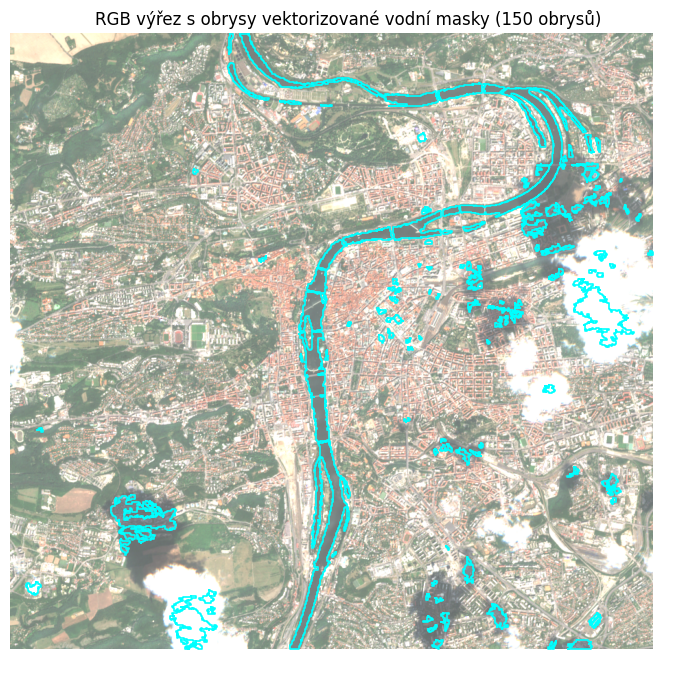

Georeferencovaný GeoTIFF 'sentinel2_praha_ndvi.tif' byl uložen (CRS: EPSG:32633).


In [9]:
from rasterio.features import shapes

# Vektorizace vodní masky (pouze pixely s hodnotou 1)
voda_uint8 = voda.astype("uint8")
tvary = list(shapes(voda_uint8, mask=(voda_uint8 == 1), transform=win_transform))
print(f"Počet vektorových útvarů (polygony vodní masky): {len(tvary)}")

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(rgb_vis)

inv_transform = ~win_transform
pocet_kreslenych = 0

for geom, val in sorted(tvary, key=lambda item: len(item[0]["coordinates"][0]), reverse=True)[:150]:
    if geom["type"] == "Polygon":
        coords = geom["coordinates"][0]
        pixel_body = [inv_transform * (pt[0], pt[1]) for pt in coords]
        cols = [p[0] for p in pixel_body]
        rows = [p[1] for p in pixel_body]
        ax.plot(cols, rows, color="cyan", linewidth=1.2)
        pocet_kreslenych += 1

ax.set_title(f"RGB výřez s obrysy vektorizované vodní masky ({pocet_kreslenych} obrysů)")
ax.axis("off")
plt.tight_layout()
plt.show()

# Export indexu NDVI jako georeferencovaného GeoTIFFu
vystup_tif = "sentinel2_praha_ndvi.tif"
ndvi_export = np.nan_to_num(ndvi, nan=-9999.0).astype("float32")

with rasterio.open(
    vystup_tif,
    "w",
    driver="GTiff",
    height=ndvi_export.shape[0],
    width=ndvi_export.shape[1],
    count=1,
    dtype="float32",
    crs=crs,
    transform=win_transform,
    nodata=-9999.0,
    compress="deflate",
) as dst:
    dst.write(ndvi_export, 1)

print(f"Georeferencovaný GeoTIFF '{vystup_tif}' byl uložen (CRS: {crs}).")

## 6. Shrnutí a prostor pro diskusi

Prošli jsme si kompletní DPZ workflow nad reálnými daty **Sentinel-2 L2A** v knihovně `rasterio`:
- načtení konkrétního výřezu přes `from_bounds` a `Window` bez nutnosti stahovat celý snímek,
- porovnání přirozených barev (**RGB**) a nepravé barevné kompozice (**CIR**),
- výpočet indexů **NDVI** a **NDWI**, analýzu rozložení hodnot na **histogramech** a pohled do **2D spektrálního prostoru (Red vs. NIR)**,
- klasifikaci povrchových tříd, výpočet ploch v hektarech, vektorizaci rastrové masky (`rasterio.features.shapes`) a export georeferencovaného **GeoTIFFu**.